# Exercitiu laborator 6 - Inferenta Bayesiana


1. **Datele si Modelul:** Vrem sa estimam rata medie $\lambda$ de apeluri pe ora. Am observat $180$ de apeluri in $10$ ore. Numarul de apeluri pe ora este modelat cu o distributie $\text{Poisson}(\lambda)$, iar pentru $\lambda$ alegem o distributie *a priori* $\text{Gamma}(\alpha_0, \beta_0)$ (in cod am pus $\alpha_0 = 1, \beta_0 = 0.1$, un prior slab informativ ca sa lasam datele sa domine).


2. **Distributia *a posteriori*:** Pentru ca Gamma si Poisson sunt distributii conjugate, distributia *a posteriori* este tot o distributie **Gamma**, unde pur si simplu adunam apelurile la $\alpha_0$ si orele la $\beta_0$:


* $\alpha_{\text{post}} = \alpha_0 + 180 = 181$


* $\beta_{\text{post}} = \beta_0 + 10 = 10.1$




3. **Cea mai probabila valoare a lui $\lambda$ (Modul):** Reprezinta vârful distributiei *a posteriori* si se calculeaza direct cu formula din enunt:



$$\text{Mod}(\lambda) = \frac{\alpha_{\text{post}} - 1}{\beta_{\text{post}}} = \frac{180}{10.1} \approx 17.82 \text{ apeluri/ora}$$





4. **Intervalul HDI de 94% (in Python):** Am generat $20.000$ de esantioane din distributia $\text{Gamma}(181, 10.1)$ folosind `scipy.stats.gamma` (cu `scale = 1 / beta_post`) si le-am pasat functiei `az.plot_posterior` din libraria ArviZ. Graficul ne arata ca, cu o probabilitate de $94\%$, rata reala $\lambda$ se afla in intervalul $[15.38, 20.50]$ apeluri pe ora.

Distributia a posteriori: Gamma(alpha = 181.0, beta = 10.1)
Media a posteriori: 17.9208
Cea mai probabila valoare a lui lambda (Modul): 17.8218
Intervalul HDI de 94%: [15.4969, 20.4832]


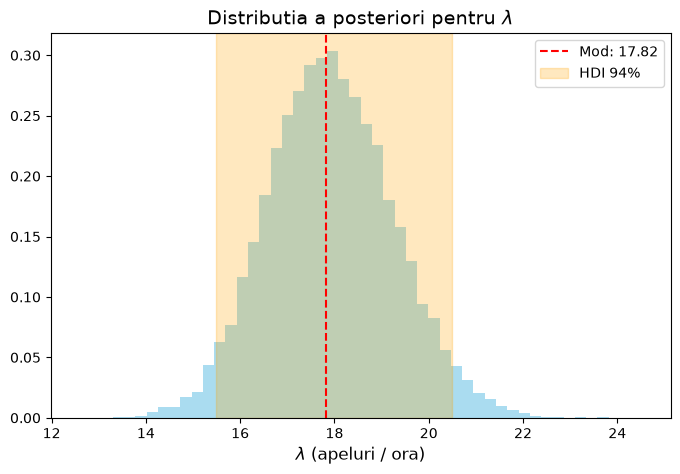

In [5]:
import numpy as np
import scipy.stats as stats
import arviz as az
import matplotlib.pyplot as plt

n_ore = 10
total_apeluri = 180

alpha_0 = 1.0
beta_0 = 0.1

alpha_post = alpha_0 + total_apeluri
beta_post = beta_0 + n_ore

print(f"Distributia a posteriori: Gamma(alpha = {alpha_post}, beta = {beta_post})")

medie_post = alpha_post / beta_post
mod_post = max(alpha_post - 1, 0) / beta_post
print(f"Media a posteriori: {medie_post:.4f}")
print(f"Cea mai probabila valoare a lui lambda (Modul): {mod_post:.4f}")

np.random.seed(42)
samples_posterior = stats.gamma.rvs(a=alpha_post, scale=1.0/beta_post, size=20000)

hdi_94 = az.hdi(samples_posterior, prob=0.94)
print(f"Intervalul HDI de 94%: [{hdi_94[0]:.4f}, {hdi_94[1]:.4f}]")

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(samples_posterior, bins=50, density=True, alpha=0.7, color="skyblue")
ax.axvline(mod_post, color="red", linestyle="--", label=f"Mod: {mod_post:.2f}")
ax.axvspan(hdi_94[0], hdi_94[1], color="orange", alpha=0.25, label="HDI 94%")

ax.legend()
ax.set_title(r"Distributia a posteriori pentru $\lambda$", fontsize=14)
ax.set_xlabel(r"$\lambda$ (apeluri / ora)", fontsize=12)
plt.show()